# Sesion 4: SIFT (Scale Invariant Feature Transform) y Descriptores

En esta sesión se tocaron los temas de la transformada de Hough y el detector de esquinas de Harris. En esta práctica se pondrán a prueba estas técnicas (o al menos su analogía) para la detección temprana de la diabetes mellitus Tipo 2, usando registros tabulares en lugar de imágenes a procesar. Este cuarderno describe el procedimiento y los resultados de la práctica de laboratorio. 

**Nota: Para representar estas técnicas en el proyecto de detección temprana de Diabetes Mellitus Tipo 2, se necesitan procesar los datos de manmera que representen una señal continua a lo largo del tiempo. Para ello, se generará una Función de "Deterioro metabólico" que representará una señal a lo largo de la vida de un "paciente mexicano promedio"**, el objetivo será detectar puntos fuertes de inflexión a la alza sobre la función de deterioro metabólico y de esta manera encontrar edades  de riesgo. 

---
## 1. Analogía de la Transformada de Hough (Votación y Acumulación de Vecindad)
* **Principio en Visión Artificial:** La Transformada de Hough estándar detecta patrones geométricos (como líneas o bordes fragmentados) mapeando los puntos de la imagen a un espacio de parámetros acumulador, donde los elementos individuales emiten "votos" y las intersecciones de alta densidad revelan estructuras globales.
* **Adaptación a la Señal Continua:** Se implementa un mecanismo de **votación por vecindad mediante una ventana deslizante de tamaño $n$**. En lugar de evaluar cada registro de forma aislada —lo cual lo haría vulnerable al ruido de medición—, cada muestra calcula su pendiente local ($\frac{dz}{dx}$) y emite votos proporcionales a su consistencia con el entorno. 
* **Significado clínico:** Detecta llos rangos de edades sobre los cuales el deterioro metabólico se dispara, es decir, indica en qué "zonas" de la vida humana existen grandes cambios en el deterioro metabólico.

---
## 2. Detector de Esquinas de Harris (Gradientes y Zonas de Inflexión)
* **Principio en Visión Artificial:** El operador de Harris identifica esquinas o puntos singulares evaluando la matriz de segundo momento (autocorrelación de gradientes espaciales en múltiples direcciones) mediante el cálculo del determinante y la traza (Respuesta de Harris $R$).
* **Adaptación a la Señal Continua:** Se calcula la derivada de primer y segundo orden de la curva de riesgo metabólico respecto a la edad ($\frac{dz}{dx}$ y $\frac{d^2z}{dx^2}$). 
* **Significado Clínico:** Funciona como un detector ultra-selectivo que señala con precisión milimétrica los **puntos de inflexión estructural**; es decir, los momentos exactos de la vida del paciente donde la tendencia del deterioro metabólico experimenta cambios abruptos en su aceleración o desaceleración.

# 📃 Configuración del Entorno y Sistema de Registro

En este bloque de código se inicializa el entorno de trabajo correspondiente a todo el notebook, 
## Sección 0
---
### 📦 Módulos y Librerías Utilizadas
| Módulo / Librería | Función Principal |
| :--- | :--- |
| **`pandas` / `numpy`** | Carga, manipulación de estructuras tabulares (`DataFrames`) y operaciones vectoriales para el cálculo de combinaciones lineales. |
| **`logging` / `traceback`** | Registro estructurado de eventos, tiempos de ejecución e historial de errores durante el cálculo del score. |
| **`datetime` / `os` / `sys` / `pathlib`** | Manejo de marcas de tiempo, rutas independientes del sistema operativo y finalización segura del script mediante `System.exit()`. |
| **`matplotlib` / `seaborn`** | Generación de visualizaciones avanzadas (curvas sigmoides, histogramas de densidad y formato visual. |
| **`sklearn.preprocessing`** | Transformación de variables continuas (`StandardScaler`) para garantizar la consistencia en la escala en las variables|

### ⚙️ Parámetros Globales y Rutas Dinámicas
* **`COMPUTER_NAME`**: Detecta automáticamente el equipo de ejecución para seleccionar dinámicamente las rutas de los datasets de entrada (`DATA_SOURCE`) y la carpeta de salida correspondiente .
* **`SEED = 32`**: Define la semilla de aleatoriedad de todo el cuaderno para garantizar la reproducibilidad exacta en el muestreo de datos para las visualizaciones.
* **`YEAR = 2021`**: Define el periodo anual de los archivos procesados.

### 📑 Configuración del Sistema de Registro (*Logging*)
1. **Reinicio de Handlers:** Elimina controladores de *log* previos en la raíz de Python para evitar mensajes duplicados en la consola.
2. **Generación del Nombre de Log:** Asigna un nombre dinámico con marca de tiempo al log resultante.
3. **Persistencia Doble:** Configura `log.basicConfig` para redirigir la salida informativa simultáneamente a un archivo codificado en **UTF-8** y a la consola para el análisis y debuggueo (*StreamHandler*).

In [89]:
# ================================================================================
# 📃 Configuración Inicial y Carga de Datos para el nuevo cuaderno (Etapa 3)
# ================================================================================

import pandas as pd
import numpy as np
import logging as log
import datetime as date
import traceback as trace
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import os
import sys as System
from sklearn.preprocessing import StandardScaler

DEBUG = True
COMPUTER_NAME = os.environ.get('COMPUTERNAME', 'DEFAULT_PC')
SAVE_LOGS = True
SAVE_CHARTS = True
CLEAN_LOGS = True
DATE = date.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
YEAR = 2021
LOG_NAME = f"Vision_Artificial_Sesion_4_SIFT_y_Operadores_{YEAR}_{DATE}.txt"
SEED=32
USE_PARQUET = True                                                # Use parquet to improve file handling

# Define Data sources and output for this notebook
if (COMPUTER_NAME == 'PC_ABRAHAM'):    
    DATA_SOURCE = Path("D:/Abraham/MyRepos/Maestria/05_Semestres/3er_Semestre/Vision_artificial/Sesion_3/Output")
    output_dir = Path("D:/Abraham/MyRepos/Maestria/05_Semestres/3er_Semestre/Vision_artificial/Sesion_4/Output")
else:
    DATA_SOURCE = Path("D:/Personal/Maestria/05_Semestres/3er_Semestre/Vision_artificial/Sesion_3/Output")
    output_dir = Path("D:/Personal/Maestria/05_Semestres/3er_Semestre/Vision_artificial/Sesion_4/Output")

# Clean handler to allow delete previous logs
for handler in log.root.handlers[:]:
    log.root.removeHandler(handler)

if CLEAN_LOGS and output_dir.exists():    
    pattern = f"Vision_Artificial_Sesion_4_SIFT_y_Operadores_{YEAR}_*.txt"
    old_logs = sorted(list(output_dir.glob(pattern)))
    if old_logs:
        print(f"\n🧹'CLEAN_LOGS' activado. Se encontraron {len(old_logs)} log(s) anterior(es).")
        for old_log in old_logs:
            try:
                old_log.unlink()
                print(f"🗑️ Eliminado: {old_log.name}")
            except Exception as e:
                print(f"⚠️ No se pudo eliminar {old_log.name}: {e}")

# Set output Directory for the resultant log_file_str
output_dir.mkdir(parents=True, exist_ok=True)
log_file_str = str(output_dir / LOG_NAME)

# Basic configuration for logger 
log.basicConfig(
    level=log.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    handlers=[
        log.FileHandler(log_file_str, encoding='utf-8'),    # File handler to write log into a file
        log.StreamHandler()                                 # Stream handler to show logs in console
    ]
)    
logger = log.getLogger()
logger.info("=" * 80)
logger.info(f"🚀 INICIANDO ETAPA DE CÁLCULO DE SCORE DE RIESGO METABÓLICO CONTINUO")
logger.info("=" * 80 + "\n\n")



2026-11-10 16:10:22,709 - INFO - ================================================================================
2026-11-10 16:10:22,710 - INFO - 🚀 INICIANDO ETAPA DE CÁLCULO DE SCORE DE RIESGO METABÓLICO CONTINUO
2026-11-10 16:10:22,711 - INFO - ================================================================================





🧹'CLEAN_LOGS' activado. Se encontraron 1 log(s) anterior(es).
🗑️ Eliminado: Vision_Artificial_Sesion_4_SIFT_y_Operadores_2021_2026-11-10_16-09-57.txt


# 📃 Carga de Datasets y Construcción de la Señal Continua de Riesgo Metabólico
Previamente, se han preprocesado varios Datasets del hospital Juarez de México que contienen registros de pacientes de cierta Edad, Sexo y comorbilidades registradas en formato CIE-10. Se usaron esos datasets para generar un Macro Dataset y sobre ese Dataset se entrenó un modelo de Regresión lineal de alta confiabilidad que asignó un valor de Beta de la regresión a cada familia de enfermedades. Bajo este modelo, se puede leer el archivo original y asignar una puntuación de Riesgo metabólico a cada registro del Dataset original, para después construir la **__Función de Riesgo Metabólico__**


En esta sección se integran los resultados del modelo de Regresión Logística previamente entrenado para transformar las variables clínicas discretas de cada paciente en un **Índice Continuo de Deterioro Metabólico ($Z$)** y su correspondiente **Probabilidad Sigmoide ($P$)**.

## Sección 1
---
### 🔧 Metodología

1. **Carga y Validación de Archivos:**
   * Busca y lee desde la carpeta de salida (`Output`) o de origen el dataset concatenado de superclases (`1_Concatenar_y_Estandarizar_HJM_Superclasses_2021.csv`) y la tabla de coeficientes exportada (`2_Regresion_logistica_DMT2_HJM_Betas_Comorbilidades_2021.csv`).
   * Valida la existencia de ambos archivos; en caso de ausencia, emite una advertencia en el *log* y detiene la ejecución mediante `System.exit()`.
2. **Estandarización Preservativa de la Edad:**
   * Se crea una copia de trabajo (`df_proc`) para aplicar `StandardScaler` sobre la columna `Edad`, asegurando que el cálculo mantenga la misma escala $Z$-score con la que se entrenó la Regresión Logística.
   * El DataFrame original (`df_orig`) se conserva intacto para no alterar la edad real en años del paciente en el reporte final.
3. **Cálculo de la Combinación Lineal (Score $Z$):**
   * Extrae el **Intercepto ($\beta_0$)** base de la columna `Interceptor` de la tabla de coeficientes.
   * Asocia cada comorbilidad con su coeficiente $\beta_i$ en un diccionario y evalúa la suma ponderada sobre el dataset:
     $$Z_j = \beta_0 + \sum_{i=1}^{n} \beta_i \cdot X_{ij}$$
4. **Transformación Sigmoide a Probabilidad ($P$):**
   * Mapea el predictor lineal $Z$ al rango probabilístico $[0, 1]$ mediante la función sigmoide:
     $$P_j = \frac{1}{1 + e^{-Z_j}}$$
5. **Asignación y Exportación:**
   * Integra los nuevos indicadores `Score_Deterioro_Metabolico_Z` y `Prob_Deterioro_Metabolico_P` al DataFrame original.
   * Registra las estadísticas descriptivas globales ($\mu, \sigma, \min, \max$) en el sistema de *logging* y exporta el archivo `3_Dataset_Con_Score_Deterioro_Metabolico_2021.csv` con formato UTF-8 (`utf-8-sig`)
6. **Visualización de Densidades**
   * Genera dos paneles de distribución (*KDE / Histplot*) segmentados por la presencia de Diabetes Mellitus Tipo 2 (`Diabetes_Mellitus_T2`):
   * **Panel Izquierdo ($Z$):** Muestra la separación en la escala continua Logit entre la población sana (dominio negativo) y la población con deterioro/diagnóstico (dominio positivo).
   * **Panel Derecho ($P$):** Muestra la distribución bimodal de las probabilidades sigmoides estimadas, guardando la figura resultante en formato de alta resolución (300 DPI).



In [90]:

try:
    logger.info("-------SECCION 1: Carga de Datasets y Tabla de Betas-------")

    # Given the names from files that should be present in output folder
    if USE_PARQUET:
        file_dataset = f"1_Concatenar_y_Estandarizar_HJM_Superclasses_{YEAR}.parquet"
        file_betas = f"2_Regresion_logistica_DMT2_HJM_Betas_Comorbilidades_{YEAR}.parquet"
    else:
        file_dataset = f"1_Concatenar_y_Estandarizar_HJM_Superclasses_{YEAR}.csv"
        file_betas = f"2_Regresion_logistica_DMT2_HJM_Betas_Comorbilidades_{YEAR}.csv"
    # Make path variable... DATA_SOURCE is nod used inthis notebook, in that case System.Exit() will be executed
    path_dataset = output_dir / file_dataset if (output_dir / file_dataset).exists() else Path(DATA_SOURCE) / file_dataset
    path_betas = output_dir / file_betas if (output_dir / file_betas).exists() else Path(DATA_SOURCE) / file_betas
    # Warning system to correct input paths
    if not path_dataset.exists():
        logger.warning(f"⚠️ No se encontró el dataset de superclases en: {path_dataset}")
        System.exit()
    if not path_betas.exists():
        logger.warning(f"⚠️ No se encontró la tabla de Betas en: {path_betas}")
        System.exit()

    # Read both files to create dataframes
    logger.info(f"⌛ Cargando Dataset de Superclases: {path_dataset.name}")
    if USE_PARQUET:
        df_orig = pd.read_parquet(path_dataset)
    else:
        df_orig = pd.read_csv(path_dataset)
    logger.info(f"✅ Dataset cargado. Dimensiones: {df_orig.shape[0]} filas x {df_orig.shape[1]} columnas.")
    logger.info(f"⌛ Cargando Tabla de Betas: {path_betas.name}")
    if USE_PARQUET:
        df_betas = pd.read_parquet(path_betas)
    else:
        df_betas = pd.read_csv(path_betas)
    logger.info(f"✅ Tabla de Betas cargada ({len(df_betas)} coeficientes registrados).")

    # "Re-standaraize" the 'Edad' variable in a secure copy
    df_proc = df_orig.copy()
    if 'Edad' in df_proc.columns:
        scaler = StandardScaler()
        df_proc['Edad'] = scaler.fit_transform(df_proc[['Edad']])
        logger.info("✅ Variable 'Edad' re-estandarizada correctamente con StandardScaler.")

    # Map comobidities to beta coefficients 
    beta_dict = dict(zip(df_betas['Comorbilidad / Variable'], df_betas['Beta (Coeficiente)']))
    # Get Intercept (Beta_0) from first row.
    beta_0 = df_betas['Interceptor'][0]         
    logger.info(f"📌 Intercepto base (Beta_0): {beta_0:.4f}")

    # Create "Metabolic degradation score" (Linear combination: Z = Beta_0 + SUM(Beta_i * X_i)) as a linear predictor for each registry
    metabolic_score = np.full(len(df_proc), beta_0, dtype=float)
    comorbidities = 0
    for col, beta in beta_dict.items():
        if col in df_proc.columns:
            # Forzar conversión a numérico para evitar errores de tipo object/string
            numeric_series = pd.to_numeric(df_proc[col], errors='coerce').fillna(0)
            beta_float = float(beta)
            metabolic_score += numeric_series.values * beta_float
            comorbidities += 1
    logger.info(f"✅ Puntuación ponderada calculada considerando {comorbidities} variables/comorbilidades.")

    # Transform Sigmoid to Probability  P = 1 / (1 + exp(-Z))
    probabilidad_metabolica = 1.0 / (1.0 + np.exp(-metabolic_score))

    # Assign both indicators to original dataframe Score and probability per registry
    df_orig['Score_Deterioro_Metabolico_Z'] = metabolic_score
    df_orig['Prob_Deterioro_Metabolico_P'] = probabilidad_metabolica
    # Print statistics
    logger.info("📊 Estadísticas de la Señal Continua de Riesgo Metabólico (Z):")
    logger.info(f"   Mínimo: {metabolic_score.min():.4f} | Máximo: {metabolic_score.max():.4f} | Media: {metabolic_score.mean():.4f} | Std: {metabolic_score.std():.4f}")
    # Just keep relevant columns for this practice
    keep_Columns = ['Edad', 'Sex', 'Sex_desc','CIE-10_1_desc','CIE-10_2_desc','CIE-10_3_desc', 'Score_Deterioro_Metabolico_Z','Prob_Deterioro_Metabolico_P','Diabetes_Mellitus_T2']
    # Drop all columns not specified
    df_filtered = df_orig.drop(columns=df_orig.columns.difference(keep_Columns))
    if DEBUG:
        print(df_filtered.head(5))

    # Export DataSet
    if USE_PARQUET:
        output_scored_path = output_dir / f"3_Dataset_Con_Score_Deterioro_Metabolico_{YEAR}.parquet"
        df_filtered.to_parquet(output_scored_path, index=False, engine='fastparquet')
    else:    
        output_scored_path = output_dir / f"3_Dataset_Con_Score_Deterioro_Metabolico_{YEAR}.csv"
        df_filtered.to_csv(output_scored_path, index=False, encoding='utf-8-sig')
    logger.info(f"💾 Dataset guardado exitosamente en: {output_scored_path}")

    logger.info("-------SECCION 1: Carga de Datasets y Tabla de Betas (FIN)-------")

except Exception as e:
    err_detail=trace.format_exc()
    logger.error(f"❌ Error durante la Carga de los datasets, Superclasses y betas:  \n{e}")
    logger.error(f"    Detalles del error: {err_detail}")

2026-11-10 16:10:22,730 - INFO - -------SECCION 1: Carga de Datasets y Tabla de Betas-------
2026-11-10 16:10:22,732 - INFO - ⌛ Cargando Dataset de Superclases: 1_Concatenar_y_Estandarizar_HJM_Superclasses_2021.parquet
2026-11-10 16:10:23,008 - INFO - ✅ Dataset cargado. Dimensiones: 87027 filas x 1184 columnas.
2026-11-10 16:10:23,009 - INFO - ⌛ Cargando Tabla de Betas: 2_Regresion_logistica_DMT2_HJM_Betas_Comorbilidades_2021.parquet
2026-11-10 16:10:23,015 - INFO - ✅ Tabla de Betas cargada (1177 coeficientes registrados).
2026-11-10 16:10:23,404 - INFO - ✅ Variable 'Edad' re-estandarizada correctamente con StandardScaler.
2026-11-10 16:10:23,410 - INFO - 📌 Intercepto base (Beta_0): 6.3613
2026-11-10 16:10:23,728 - INFO - ✅ Puntuación ponderada calculada considerando 1177 variables/comorbilidades.
2026-11-10 16:10:23,731 - INFO - 📊 Estadísticas de la Señal Continua de Riesgo Metabólico (Z):
2026-11-10 16:10:23,732 - INFO -    Mínimo: -10.4302 | Máximo: 7.1464 | Media: -2.1583 | Std: 1.

   Edad Sex Sex_desc                                      CIE-10_1_desc  \
0    20   2    Mujer  OTRAS GASTROENTERITIS Y COLITIS DE ORIGEN INFE...   
1    20   2    Mujer  OTRAS GASTROENTERITIS Y COLITIS DE ORIGEN INFE...   
2    20   1   Hombre  GASTROENTERITIS Y COLITIS DE ORIGEN NO ESPECIF...   
3    20   1   Hombre  GASTROENTERITIS Y COLITIS DE ORIGEN NO ESPECIF...   
4    20   2    Mujer  GASTROENTERITIS Y COLITIS DE ORIGEN NO ESPECIF...   

                                       CIE-10_2_desc CIE-10_3_desc  \
0  OTRAS ENFERMEDADES INFECCIOSAS Y PARASITARIAS ...      sin dato   
1                                           sin dato      sin dato   
2                                           sin dato      sin dato   
3                                           sin dato      sin dato   
4                                           sin dato      sin dato   

   Diabetes_Mellitus_T2  Score_Deterioro_Metabolico_Z  \
0                     0                     -4.454755   
1             

2026-11-10 16:10:23,830 - INFO - -------SECCION 2: Separación del Dataset por género -------
2026-11-10 16:10:23,854 - INFO - Valores de la columna 'Sex' convertidos a números enteros (2 y 1)
2026-11-10 16:10:23,945 - INFO - ✅ Registros separados -> Hombres: 28985 | Mujeres: 58042
C:\Users\Abrah\AppData\Local\Temp\ipykernel_3868\3957311471.py:24: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_group.rename(columns={'Score_Deterioro_Metabolico_Z': 'Score_Z'}, inplace=True)
C:\Users\Abrah\AppData\Local\Temp\ipykernel_3868\3957311471.py:24: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_group.rename(columns={'Score_Deterioro_Metabolico_Z': 'Sco

   Edad   Score_Z  gradient
0    20 -2.918086  0.055712
1    21 -2.862374  0.000323
2    22 -2.917440  0.031674
3    23 -2.799026 -0.028591
4    24 -2.974622  0.063198
   Edad   Score_Z  gradient
0    20 -3.096457  0.024085
1    21 -3.072371 -0.025510
2    22 -3.147477  0.011007
3    23 -3.050358  0.026930
4    24 -3.093616 -0.020543


2026-11-10 16:10:24,389 - INFO - 📊 Gráfica guardada exitosamente en: D:\Abraham\MyRepos\Maestria\05_Semestres\3er_Semestre\Vision_artificial\Sesion_4\Output\Grafica_Deterioro_Metabolico_Hombres_Mujeres_2021.png


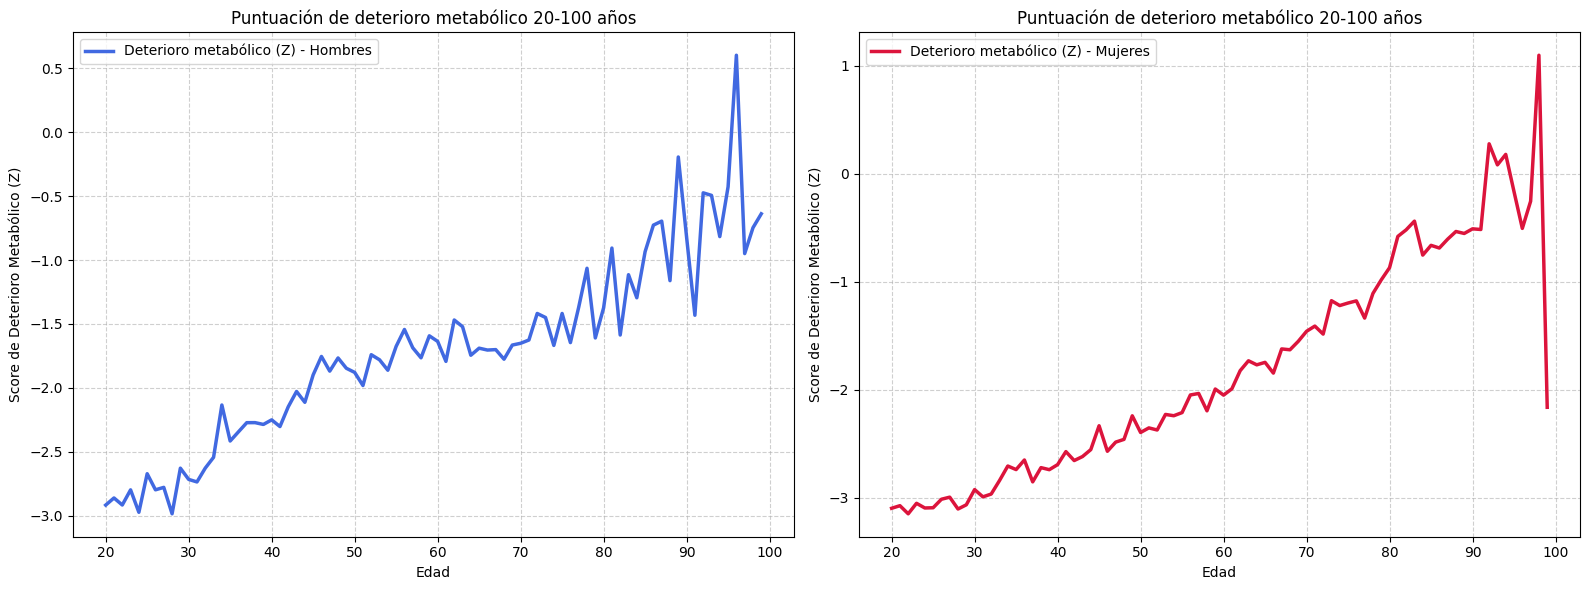

2026-11-10 16:10:24,522 - INFO - -------SECCION 2: Separación del Dataset por género (FIN)-------


In [91]:
logger.info("-------SECCION 2: Separación del Dataset por género -------")
try:
    # Convert 'Sex' column to numbers
    df_filtered["Sex"] = pd.to_numeric(df_filtered["Sex"], errors="coerce")
    logger.info(f"Valores de la columna 'Sex' convertidos a números enteros (2 y 1)")
    filtro_hombres_val = 1
    filtro_mujeres_val = 2

    df_hombres = df_filtered[df_filtered["Sex"] == filtro_hombres_val].copy()
    df_mujeres = df_filtered[df_filtered["Sex"] == filtro_mujeres_val].copy()

    logger.info(f"✅ Registros separados -> Hombres: {len(df_hombres)} | Mujeres: {len(df_mujeres)}") 
    # Function to calculate the metabolic signal 
    def procesar_senal_metabolica(df_subset):
        # Group data set by 'Edad' field, this will allow to take the average of Score Z 
        df_group = (
            df_subset.groupby("Edad")["Score_Deterioro_Metabolico_Z"]
            .mean()
            .reset_index()
        )
        df_group = df_group.sort_values("Edad")
        # La señal continua es directamente la serie promedio por edad
        # df_group["Score_Z"] = df_group["Score_Deterioro_Metabolico_Z"]
        df_group.rename(columns={'Score_Deterioro_Metabolico_Z': 'Score_Z'}, inplace=True)

        # Cálculus of the gradient per each Score Z step (Edad)
        df_group["gradient"] = np.gradient(df_group["Score_Z"], df_group["Edad"])
        return df_group

    # Procesar ambos perfiles
    data_men = procesar_senal_metabolica(df_hombres)
    data_women = procesar_senal_metabolica(df_mujeres)

    if DEBUG:
        print(data_men.head(5))
        print(data_women.head(5))

    # 3. Generación de Gráficas Comparativas
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

    # Gráfica Hombres
    sns.lineplot(
        data=data_men,
        x="Edad",
        y="Score_Z",
        ax=axes[0],
        color="royalblue",
        linewidth=2.5,
        label="Deterioro metabólico (Z) - Hombres",
    )
    axes[0].set_title(
        "Puntuación de deterioro metabólico 20-100 años", fontsize=12
    )
    axes[0].set_xlabel("Edad", fontsize=10)
    axes[0].set_ylabel("Score de Deterioro Metabólico (Z)", fontsize=10)
    axes[0].legend()
    axes[0].grid(True, linestyle="--", alpha=0.6)

    # Gráfica Mujeres
    sns.lineplot(
        data=data_women,
        x="Edad",
        y="Score_Z",
        ax=axes[1],
        color="crimson",
        linewidth=2.5,
        label="Deterioro metabólico (Z) - Mujeres",
    )
    axes[1].set_title(
        "Puntuación de deterioro metabólico 20-100 años", fontsize=12
    )
    axes[1].set_xlabel("Edad", fontsize=10)
    axes[1].set_ylabel("Score de Deterioro Metabólico (Z)", fontsize=10)
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()

    # Guardar la figura generada
    output_fig_path = (
        output_dir / f"Grafica_Deterioro_Metabolico_Hombres_Mujeres_{YEAR}.png"
    )
    plt.savefig(output_fig_path, dpi=300)
    logger.info(f"📊 Gráfica guardada exitosamente en: {output_fig_path}")
    plt.show()

    logger.info("-------SECCION 2: Separación del Dataset por género (FIN)-------")
except Exception as e:
    err_detail=trace.format_exc()
    logger.error(f"❌ Error durante la división del dataset:  \n{e}")
    logger.error(f"    Detalles del error: {err_detail}")

In [92]:
try:
    logger.info("-------SECCION 3: Analogía del análisis de Hough -------")

    # Fixed window to Hough Analisis (w_size*2)
    w_size = 15
    top_keys=90

    def apply_accum_hough(df_agrupado, w_size, top_keys):
        z_signal = df_agrupado["Score_Z"].values
        slopes = df_agrupado["gradient"].values

        # Creates acumulator votes and slopes tensors of signal size
        accumulator_votes = np.zeros_like(z_signal)
        global_median = np.median(z_signal)
        # For each "i" series (edad) value of Score Z signal...
        for i in range(w_size, len(z_signal) - w_size):
            # Slopes and values of Z signal are set to a portion of the tensor (2 times the window)
            neighborhood_slopes = slopes[i - w_size : i + w_size]
            neighborhood_Z_values = z_signal[i - w_size : i + w_size]

            # Set vote strength by searching how much "i" events are above Score Z, then, multiply the number of events (np.sum) by gradient mean
            vote_strength = np.mean(neighborhood_slopes) * np.sum(neighborhood_Z_values > global_median)
            # Set each acummulator as the major value between 0 and the strength vote. 
            accumulator_votes[i] = max(0, vote_strength)

        # Normalize acummulator tensor between 0 and 1, to allow compare percentages in the next step
        acc_min, acc_max = accumulator_votes.min(), accumulator_votes.max()
        if acc_max - acc_min > 1e-8:
            accumulator_norm = (accumulator_votes - acc_min) / (acc_max - acc_min + 1e-8)
        else:
            accumulator_norm = np.zeros_like(accumulator_votes)

        # Dynamic threshoold: Select the top 10% of the accumulator values (previously normalized) to get the keypoints along the whole age series
        threshold_val = np.percentile(accumulator_norm, top_keys)
        # An event is when the accumulator is greater or equal to the threshold
        events = accumulator_norm >= threshold_val

        # Save results in a copy of the dataframe
        df_result = df_agrupado.copy()
        df_result["accumulator_norm"] = accumulator_norm
        df_result["is_keypoint"] = events
        return df_result, threshold_val


    # Aplicar la lógica de Hough a ambos perfiles de forma independiente
    data_men_hough, threshold_men = apply_accum_hough(data_men, w_size, top_keys)
    k_men = data_men_hough["is_keypoint"].sum()
    data_women_hough, threshold_women = apply_accum_hough(data_women, w_size, top_keys)
    k_women = data_women_hough["is_keypoint"].sum()

    logger.info(
    f"✅ Análisis de Hough (Top 10%) completado:"
    f"\n   - Hombres: {k_men} keypoints detectados (Umbral {top_keys}%:"
    f" {threshold_men:.4f})"
    f"\n   - Mujeres: {k_women} keypoints detectados (Umbral {top_keys}%:"
    f" {threshold_women:.4f})\n"
    )

    if DEBUG:
        # To show all rows and columns, only for debug
        with pd.option_context("display.max_rows",None,"display.max_columns",None,"display.width",1000,):
            logger.info("🔍 [DEBUG] Inspección completa del dataset de Hombres (Hough):")
            logger.info(f"{data_men_hough}\n")
            logger.info("🔍 [DEBUG] Inspección completa del dataset de Mujeres (Hough):")
            logger.info(f"{data_women_hough}\n")
    logger.info("-------SECCION 3: Analogía del análisis de Hough (FIN)-------")

except Exception as e:
    err_detail=trace.format_exc()
    logger.error(f"❌ Error durante el análisis de Hough:  \n{e}")
    logger.error(f"    Detalles del error: {err_detail}")
  

2026-11-10 16:10:24,539 - INFO - -------SECCION 3: Analogía del análisis de Hough -------
2026-11-10 16:10:24,544 - INFO - ✅ Análisis de Hough (Top 10%) completado:
   - Hombres: 8 keypoints detectados (Umbral 90%: 0.5169)
   - Mujeres: 8 keypoints detectados (Umbral 90%: 0.7119)

2026-11-10 16:10:24,545 - INFO - 🔍 [DEBUG] Inspección completa del dataset de Hombres (Hough):
2026-11-10 16:10:24,548 - INFO -     Edad   Score_Z  gradient  accumulator_norm  is_keypoint
0     20 -2.918086  0.055712          0.000000        False
1     21 -2.862374  0.000323          0.000000        False
2     22 -2.917440  0.031674          0.000000        False
3     23 -2.799026 -0.028591          0.000000        False
4     24 -2.974622  0.063198          0.000000        False
5     25 -2.672629  0.088021          0.000000        False
6     26 -2.798579 -0.053430          0.000000        False
7     27 -2.779488 -0.093874          0.000000        False
8     28 -2.986328  0.075122          0.000000    

2026-11-10 16:10:24,572 - INFO - -------SECCION 4: Visualización de Keypoints y Descriptor por gradientes -------
2026-11-10 16:10:24,574 - INFO - 🎯 Pico máximo de Hough detectado en los hombres a los 81 años (Intensidad:1.0000)
2026-11-10 16:10:24,575 - INFO - 📏 Rango crítico centrado (±15 años): [66, 96] años
2026-11-10 16:10:24,897 - INFO - 📊 Gráfica de keypoints guardada en: D:\Abraham\MyRepos\Maestria\05_Semestres\3er_Semestre\Vision_artificial\Sesion_4\Output\Keypoints_Hough_Hombres_Descriptor_2021.png


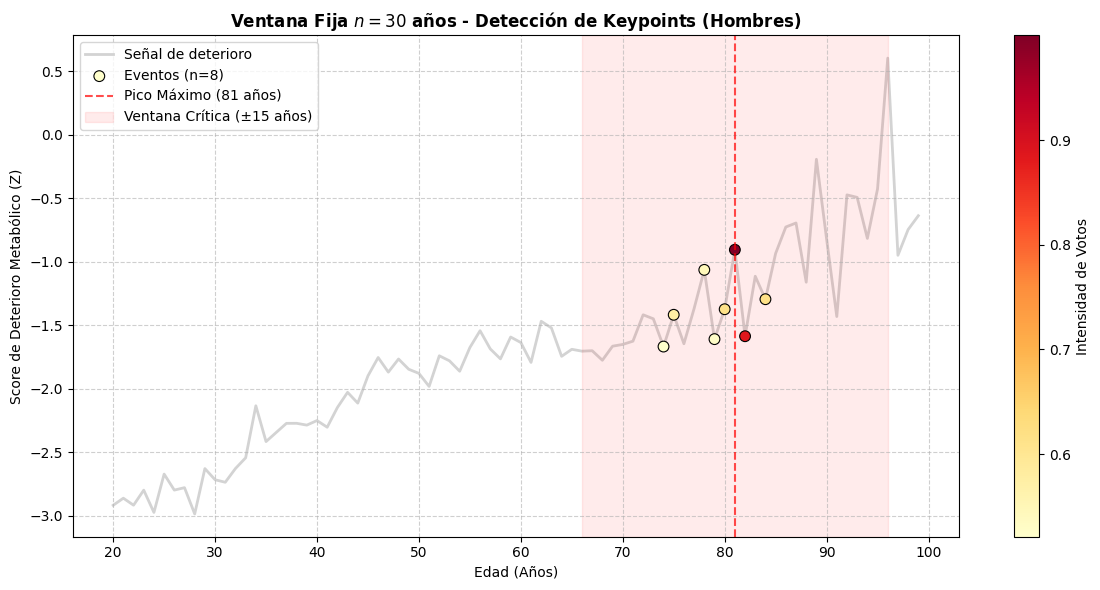

2026-11-10 16:10:25,006 - INFO - 🔗 Resultado del Matching Geométrico con Gradientes (Coseno):
   - Similitud de Coseno Máxima: 0.5251
   -🎯 Edad equivalente en Mujeres basada la similitud del coseno: 48 años
   -📏 Rango crítico centrado (±15 años): [33, 63] años
2026-11-10 16:10:25,007 - INFO - -------SECCION 4: Visualización y Descriptor por gradientes (FIN)-------


In [93]:
from sklearn.metrics.pairwise import cosine_similarity

try:
    logger.info("-------SECCION 4: Visualización de Keypoints y Descriptor por gradientes -------")
    # Select idx with max hough voting strenght ±15 years 
    idx_max_vote = data_men_hough["accumulator_norm"].idxmax()
    # Get peak age by isolating the idx_max_vote
    age_peak = data_men_hough.loc[idx_max_vote, "Edad"]
    # Get hough max vote by isolating the idx_max_vote
    hough_max_vote = data_men_hough.loc[idx_max_vote, "accumulator_norm"]

    # Define minimum and maximum range
    age_min_range = age_peak - w_size
    age_max_range = age_peak + w_size

    logger.info(f"🎯 Pico máximo de Hough detectado en los hombres a los {age_peak} años (Intensidad:{hough_max_vote:.4f})")
    logger.info(f"📏 Rango crítico centrado (±{w_size} años): [{age_min_range}, {age_max_range}] años")

    # Generation of keypoints for Z Score 
    fig, ax = plt.subplots(figsize=(12, 6))

    # Baseline signal of men Score Z 
    ax.plot(
        data_men_hough["Edad"],
        data_men_hough["Score_Z"],
        color="lightgray",
        linewidth=2.0,
        label="Señal de deterioro",
        zorder=1,)

    # Filter only keypoints = True 
    df_keypoints_men = data_men_hough[data_men_hough["is_keypoint"] == True]

    # Scatter plot for events with color scale bar accorting to votting weight
    sc = ax.scatter(
        df_keypoints_men["Edad"],
        df_keypoints_men["Score_Z"],
        c=df_keypoints_men["accumulator_norm"],
        cmap="YlOrRd",
        s=60,
        edgecolors="black",
        linewidths=0.8,
        zorder=2,
        label=f"Eventos (n={len(df_keypoints_men)})",)

    # Color bar
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label("Intensidad de Votos", fontsize=10)

    ax.set_title(
        f"Ventana Fija $n = {w_size*2}$ años - Detección de Keypoints (Hombres)",
        fontsize=12,
        fontweight="bold",)
    ax.set_xlabel("Edad (Años)", fontsize=10)
    ax.set_ylabel("Score de Deterioro Metabólico (Z)", fontsize=10)
    ax.legend(loc="upper left")
    ax.grid(True, linestyle="--", alpha=0.6)

    ax.axvline(
        x=age_peak, 
        color='red', 
        linestyle='--', 
        linewidth=1.5, 
        alpha=0.7, 
        label=f'Pico Máximo ({age_peak} años)'
    )
    
    # Opcional: Agregar un sombreado translúcido para el rango crítico [age_min_range, age_max_range]
    ax.axvspan(
        age_min_range, 
        age_max_range, 
        color='red', 
        alpha=0.08, 
        label=f'Ventana Crítica (±{w_size} años)'
    )
    
    # Actualizar la leyenda para que incluya los nuevos elementos de referencia
    ax.legend(loc="upper left")
    

    plt.tight_layout()
    output_fig_hombres = (output_dir / f"Keypoints_Hough_Hombres_Descriptor_{YEAR}.png")
    plt.savefig(output_fig_hombres, dpi=300)
    logger.info(f"📊 Gráfica de keypoints guardada en: {output_fig_hombres}")
    plt.show()

    # Build descriptor by selecting a subset where the 'Edad' filed is major than minimum range and minor than maximum range
    df_descriptor_subset = data_men_hough[(data_men_hough["Edad"] >= age_min_range)&(data_men_hough["Edad"] <= age_max_range)]
    # Then, construct the template vector by using the gradient of men group
    template_descriptor = df_descriptor_subset["gradient"].values

    # Initialize variables to really low values to ensure any match will overwrite these variables
    best_match = -1.0
    age_match = None
    # Get gradient and ages for full women data
    gradient_women_full = data_women_hough["gradient"].values  
    women_ages_full = data_women_hough["Edad"].values

    descriptor_size = len(template_descriptor)
    # Iterations between 0 until 79-31=48, +1 to compare last index
    for i in range(len(gradient_women_full) - descriptor_size + 1):
        # For each iteration, get a "window/Slice" of women gradients 
        women_slice = gradient_women_full[i : i + descriptor_size]

        # if all Women and template slice are filled with zeros, just set best match to 1 directly 
        if np.all(women_slice == 0) and np.all(template_descriptor == 0):
            sim = 1.0
        # Otherwise, apply cosine_similarity function to fit the windows
        else:
            sim = cosine_similarity(template_descriptor.reshape(1, -1), women_slice.reshape(1, -1))[0, 0]
        if sim > best_match:
            best_match = sim
            age_match = women_ages_full[i + descriptor_size // 2]

    logger.info(
        f"🔗 Resultado del Matching Geométrico con Gradientes (Coseno):"
        f"\n   - Similitud de Coseno Máxima: {best_match:.4f}"
        f"\n   -🎯 Edad equivalente en Mujeres basada la similitud del coseno: {age_match} años"
        f"\n   -📏 Rango crítico centrado (±{w_size} años): [{age_match-w_size}, {age_match+w_size}] años")
    
    logger.info("-------SECCION 4: Visualización y Descriptor por gradientes (FIN)-------")
except Exception as e:
    err_detail=trace.format_exc()
    logger.error(f"❌ Error durante la visualización del análisis de Hough:  \n{e}")
    logger.error(f"    Detalles del error: {err_detail}")

2026-11-10 16:10:25,024 - INFO - -------SECCION 5: Gráfica Comparativa de Matching en Mujeres-------
2026-11-10 16:10:25,026 - INFO - 🎯 Pico máximo de Hough detectado en las mujeres a los 83 años (Intensidad:1.0000)
2026-11-10 16:10:25,352 - INFO - 📊 Gráfica comparativa de mujeres guardada en: D:\Abraham\MyRepos\Maestria\05_Semestres\3er_Semestre\Vision_artificial\Sesion_4\Output\Keypoints_Hough_Mujeres_Matching_2021.png


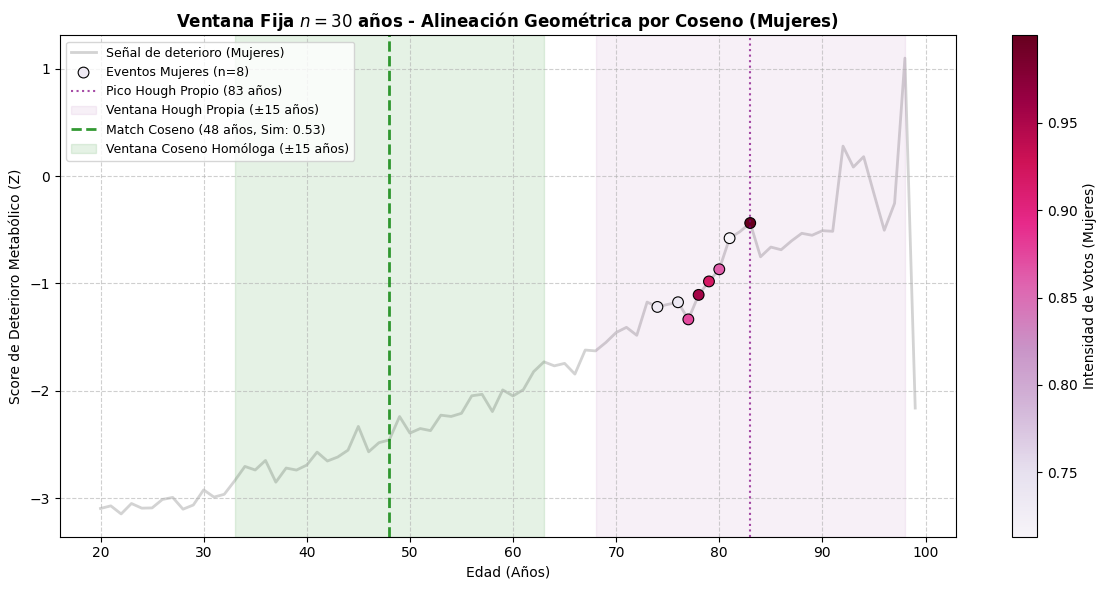

2026-11-10 16:10:25,457 - INFO - -------SECCION 5: Gráfica Comparativa de Matching en Mujeres (FIN)-------


In [94]:
# --- SECCION 5: Visualización del Matching Geométrico en Mujeres ---
try:
    logger.info("-------SECCION 5: Gráfica Comparativa de Matching en Mujeres-------")

    # 1. Encontrar el pico máximo de Hough propio de las mujeres (para referencia local)
    idx_max_vote_women = data_women_hough["accumulator_norm"].idxmax()
    age_peak_women = data_women_hough.loc[idx_max_vote_women, "Edad"]
    hough_max_vote_women = data_women_hough.loc[idx_max_vote_women, "accumulator_norm"]

    logger.info(f"🎯 Pico máximo de Hough detectado en las mujeres a los {age_peak_women} años (Intensidad:{hough_max_vote_women:.4f})")

    # Rango crítico propio de las mujeres basado en su propio Hough
    age_min_range_women = age_peak_women - w_size
    age_max_range_women = age_peak_women + w_size

    # 2. Generación de la gráfica de keypoints y la ventana de Coseno para Mujeres
    fig, ax = plt.subplots(figsize=(12, 6))

    # Señal base de deterioro de las mujeres (Score Z)
    ax.plot(
        data_women_hough["Edad"],
        data_women_hough["Score_Z"],
        color="lightgray",
        linewidth=2.0,
        label="Señal de deterioro (Mujeres)",
        zorder=1
    )

    # Filtrar keypoints = True en mujeres
    df_keypoints_women = data_women_hough[data_women_hough["is_keypoint"] == True]

    # Gráfica de dispersión de eventos con su barra de color
    sc_w = ax.scatter(
        df_keypoints_women["Edad"],
        df_keypoints_women["Score_Z"],
        c=df_keypoints_women["accumulator_norm"],
        cmap="PuRd", # Tono púrpura/rosado para diferenciar de los hombres
        s=60,
        edgecolors="black",
        linewidths=0.8,
        zorder=2,
        label=f"Eventos Mujeres (n={len(df_keypoints_women)})"
    )

    # Barra de color
    cbar_w = plt.colorbar(sc_w, ax=ax)
    cbar_w.set_label("Intensidad de Votos (Mujeres)", fontsize=10)

    ax.set_title(
        f"Ventana Fija $n = {w_size*2}$ años - Alineación Geométrica por Coseno (Mujeres)",
        fontsize=12,
        fontweight="bold"
    )
    ax.set_xlabel("Edad (Años)", fontsize=10)
    ax.set_ylabel("Score de Deterioro Metabólico (Z)", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.6)

    # -------------------------------------------------------------
    # REFERENCIA A: Pico y Rango propio de Hough en Mujeres
    # -------------------------------------------------------------
    ax.axvline(
        x=age_peak_women, 
        color='purple', 
        linestyle=':', 
        linewidth=1.5, 
        alpha=0.7, 
        label=f'Pico Hough Propio ({age_peak_women} años)'
    )
    ax.axvspan(
        age_min_range_women, 
        age_max_range_women, 
        color='purple', 
        alpha=0.06, 
        label=f'Ventana Hough Propia (±{w_size} años)'
    )

    # -------------------------------------------------------------
    # REFERENCIA B: Pico y Rango homólogo obtenido por Similitud de Coseno
    # -------------------------------------------------------------
    match_min_range = age_match - w_size
    match_max_range = age_match + w_size

    ax.axvline(
        x=age_match, 
        color='green', 
        linestyle='--', 
        linewidth=2.0, 
        alpha=0.8, 
        label=f'Match Coseno ({age_match} años, Sim: {best_match:.2f})'
    )
    ax.axvspan(
        match_min_range, 
        match_max_range, 
        color='green', 
        alpha=0.10, 
        label=f'Ventana Coseno Homóloga (±{w_size} años)'
    )

    ax.legend(loc="upper left", fontsize=9)

    plt.tight_layout()
    output_fig_mujeres = (output_dir / f"Keypoints_Hough_Mujeres_Matching_{YEAR}.png")
    plt.savefig(output_fig_mujeres, dpi=300)
    logger.info(f"📊 Gráfica comparativa de mujeres guardada en: {output_fig_mujeres}")
    plt.show()

    logger.info("-------SECCION 5: Gráfica Comparativa de Matching en Mujeres (FIN)-------")

except Exception as e:
    err_detail = trace.format_exc() if "trace`" in globals() or "trace_back" in locals() else str(e)
    logger.error(f"❌ Error durante la generación de la gráfica de mujeres: \n{e}")
    logger.error(f"    Detalles del error: {err_detail}")

In [ ]:
# Sesion 4: Operador SIFT y descriptores
